# **Heap Sort**

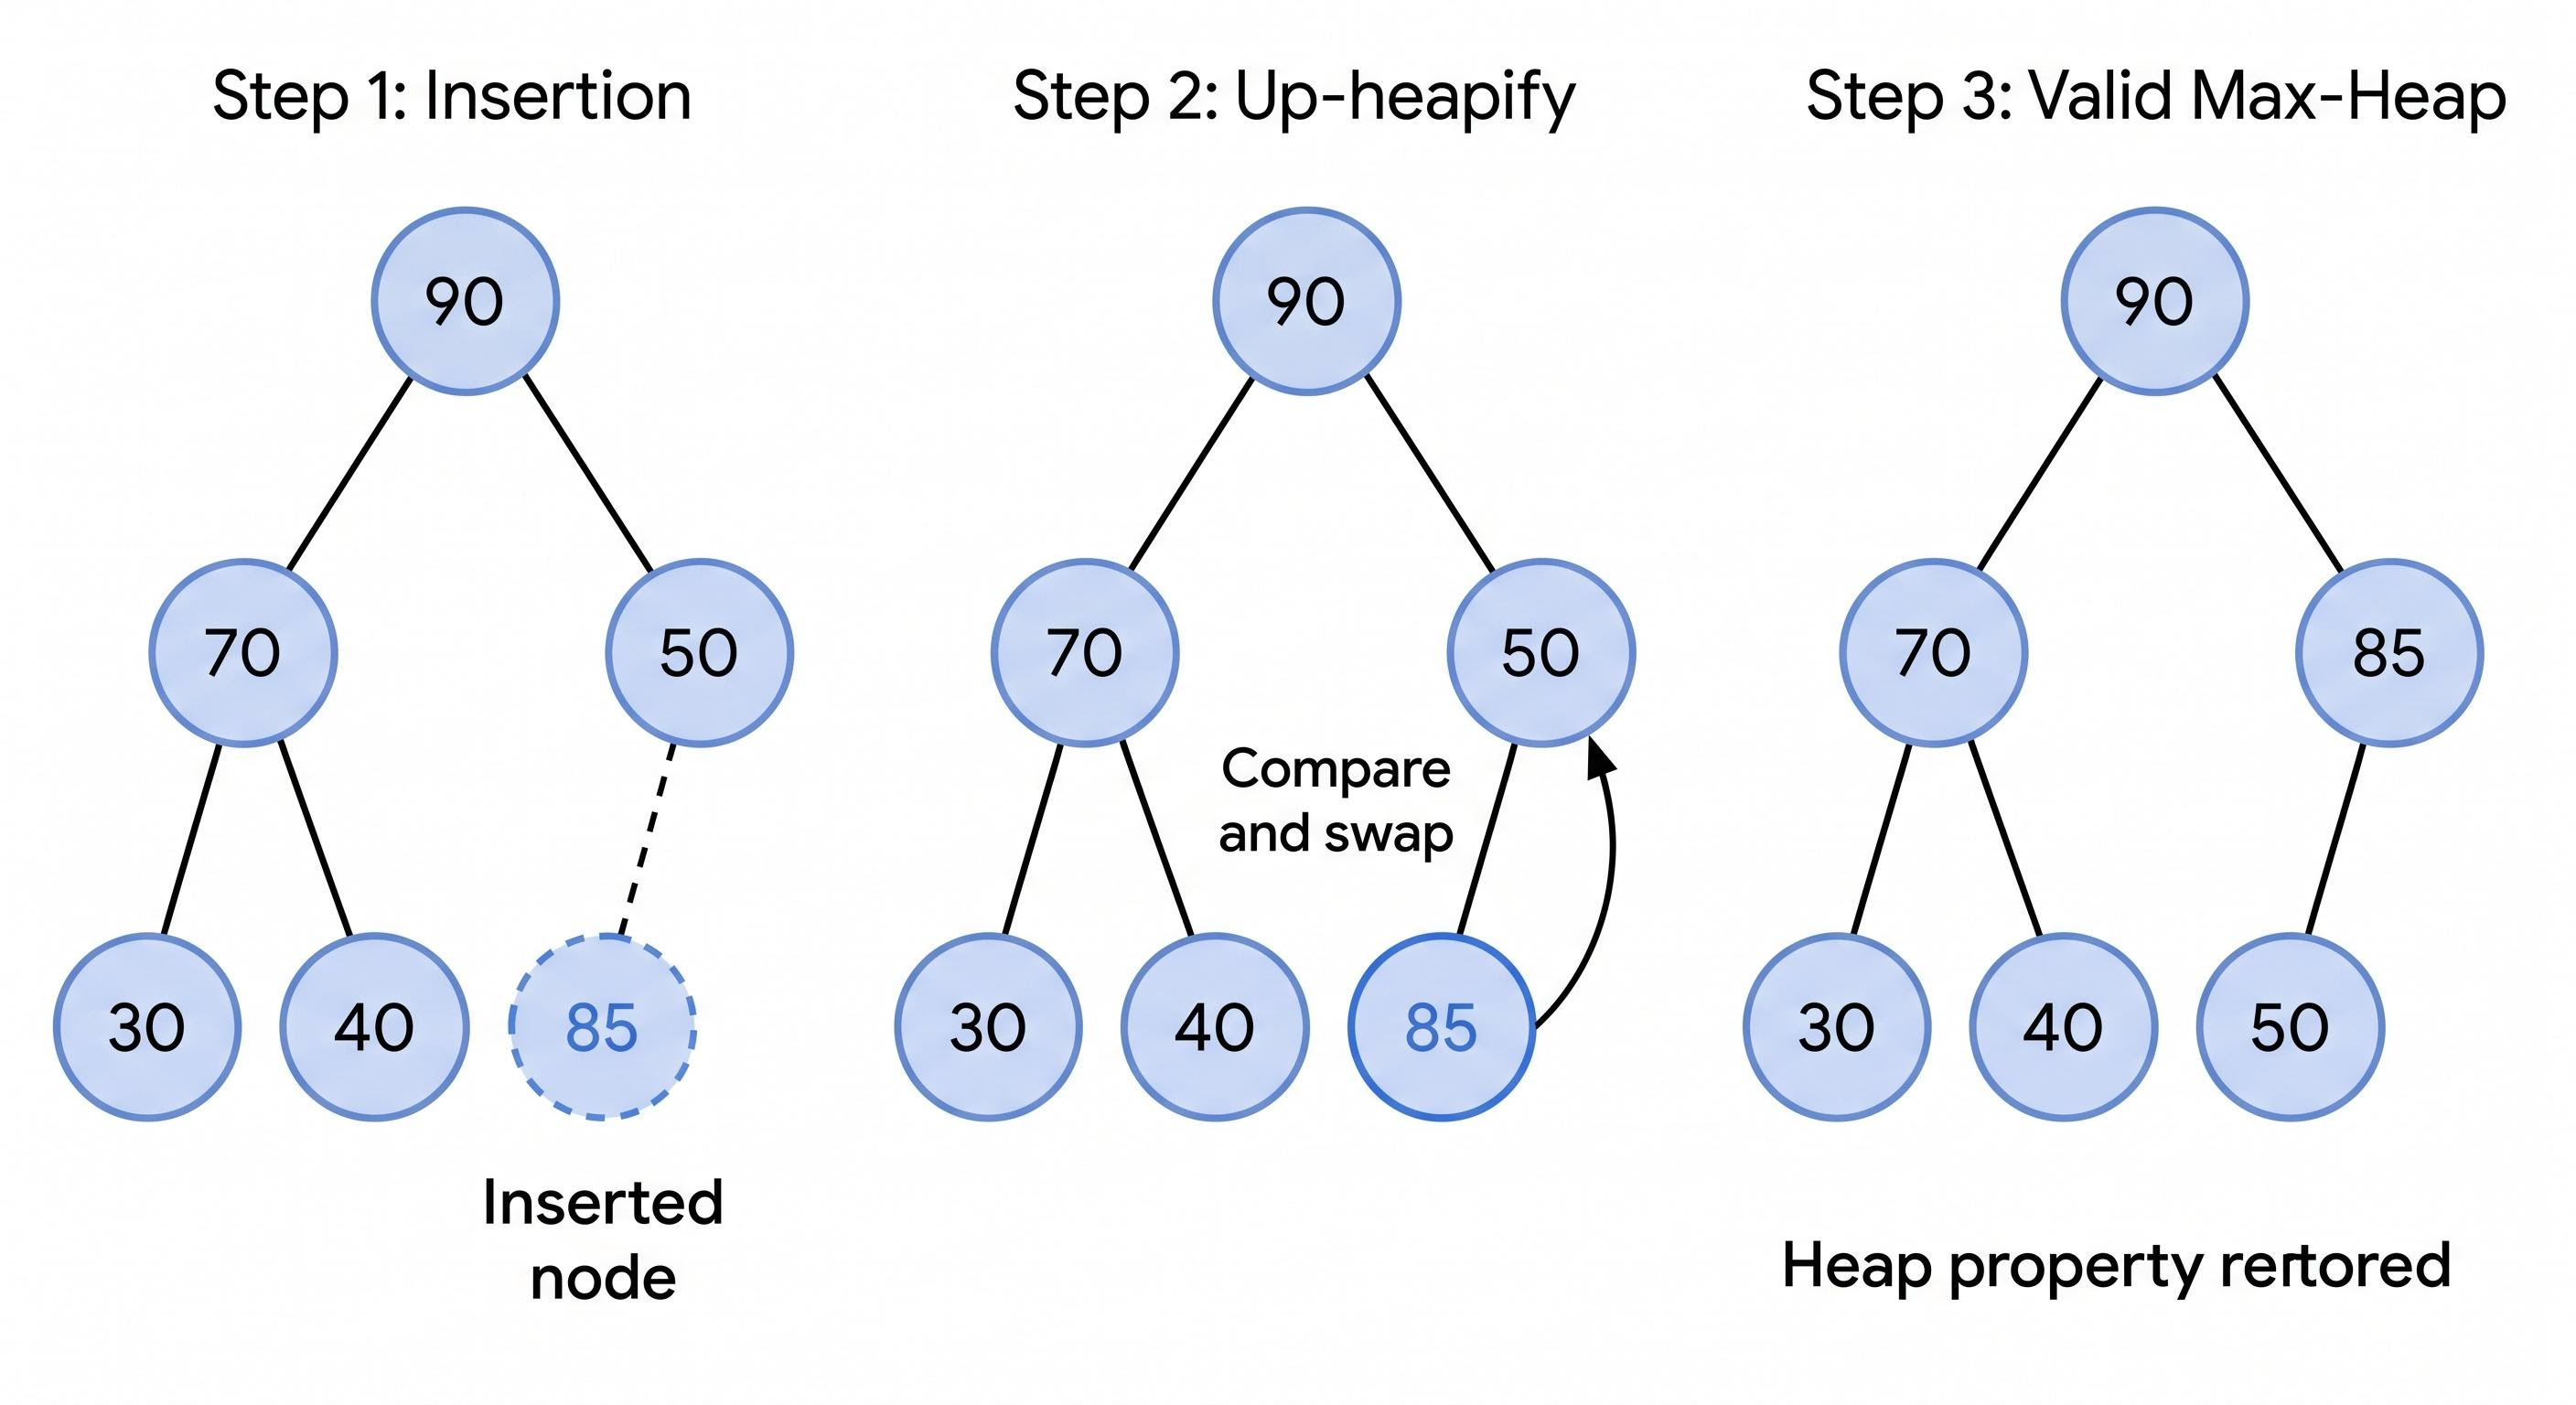

### 1. Definición y Conceptos Clave
El Heap Sort es un algoritmo de ordenamiento basado en comparación que utiliza una estructura de datos llamada Montículo (Heap) , la cual es un árbol binario casi completo que cumple con la propiedad de los montículos:

* Max-Heap (Montículo Máximo): El valor de cada nodo padre es mayor o igual  que el de sus hijos. Por lo tanto, el elemento máximo siempre se encuentra en la raíz ($A[0]$).

* Min-Heap (Montículo Mínimo): El valor de cada nodo padre es menor o igual que el de sus hijos (la raíz es el mínimo).

Para Heap Sort, comúnmente utilizamos un Max-Heap si queremos ordenar de forma ascendente.

### Pasos Generales del Algoritmo:

1. Construir un Max-Heap a partir de los datos desordenados.

2. Intercambiar el elemento de la raíz (el mayor) con el último elemento del heap.

3. Reducir el tamaño del montón en 1 (para "sacar" el elemento ya ordenado).

4. Hacer Heapify (reajustar el montículo) en la nueva raíz para restaurar la propiedad de Max-Heap.

5. Repita los pasos 2 al 4 hasta que el montón tenga tamaño 1.

### 2. Analogía para la Clase
Imagina que estás organizando un torneo de lucha libre o una competencia de pesas en una escuela:

Fase 1 (Construir el Montículo): Pones a todos los estudiantes en un árbol de eliminación. Vas organizando al grupo de abajo hacia arriba asegurándote de que en cada "pareja o trío", el más fuerte (el número más alto) quede arriba. Al final, el estudiante más fuerte de todo el colegio queda en la cima (la raíz).

Fase 2 (Extraer y Reordenar): Sacas al campeón de la cima y lo mandas al final de la fila (el lugar de los ya graduados/ordenados). El estudiante que había quedado más abajo de la jerarquía sube temporalmente a la cima, pero como probablemente no es el más fuerte, lo haces "competir" hacia abajo ( heapify ) para que el siguiente más fuerte vuelva a subir a la cima.

Repites esto hasta que todos queden ordenados de menor a mayor en la fila final.

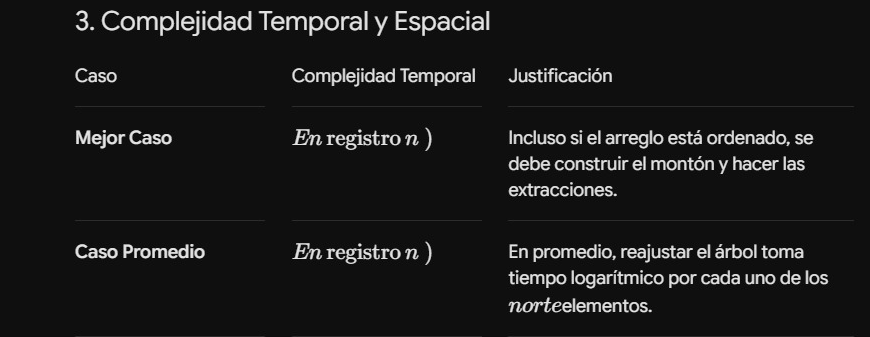

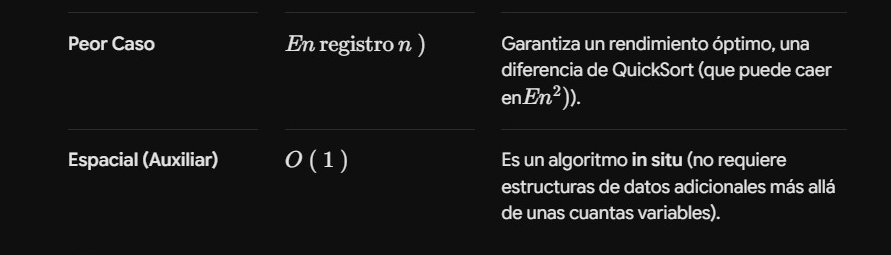

### Celda 1: Visualizar la estructura del Arreglo como un Árbol (Fórmula de Índices)
Antes de ordenar, es vital entender cómo pasamos de una lista lineal (arreglo) a un árbol binario imaginario usando las posiciones (índices).

In [ ]:
# Celda 1: Cómo encontrar padres e hijos en un arreglo
def mostrar_relaciones(arreglo, indice):
    n = len(arreglo)
    izq = 2 * indice + 1
    der = 2 * indice + 2
    padre = (indice - 1) // 2

    print(f"Nodo actual: {arreglo[indice]} (en el índice {indice})")

    if padre >= 0 and indice > 0:
        print(f"  -> Su padre es: {arreglo[padre]}")
    else:
        print("  -> Es la raíz (no tiene padre)")

    if izq < n:
        print(f"  -> Su hijo izquierdo es: {arreglo[izq]}")
    if der < n:
        print(f"  -> Su hijo derecho es: {arreglo[der]}")

# Ejemplo sencillo:
datos = [10, 5, 8, 2, 1]
mostrar_relaciones(datos, 0)  # Analizamos la raíz (10)

Nodo actual: 10 (en el índice 0)
  -> Es la raíz (no tiene padre)
  -> Su hijo izquierdo es: 5
  -> Su hijo derecho es: 8


### Celda 2: La función básica heapify(Mantener la regla del Max-Heap)
Esta es la función más importante:corrige a un solo nodo si es más pequeño que sus hijos,obligándolo a "hundirse" hasta su posición correcta.

In [ ]:
# Celda 2: Hundir un elemento para cumplir la regla del Max-Heap
def heapify_simple(arr, n, i):
    mayor = i          # Asumimos que la raíz es el mayor
    izq = 2 * i + 1    # Índice del hijo izquierdo
    der = 2 * i + 2    # Índice del hijo derecho

    # Si el hijo izquierdo existe y es mayor que el actual "mayor"
    if izq < n and arr[izq] > arr[mayor]:
        mayor = izq

    # Si el hijo derecho existe y es mayor que el actual "mayor"
    if der < n and arr[der] > arr[mayor]:
        mayor = der

    # Si el mayor no era la raíz, intercambiamos y repetimos abajo
    if mayor != i:
        arr[i], arr[mayor] = arr[mayor], arr[i] # Intercambio (swap)
        print(f"Estado parcial del arreglo tras intercambio: {arr}")
        heapify_simple(arr, n, mayor)

# Ejemplo de uso aislado:
mi_arbol_roto = [3, 10, 5, 1, 2]
print("Antes de heapify:", mi_arbol_roto)
heapify_simple(mi_arbol_roto, len(mi_arbol_roto), 0)
print("Después de heapify en la raíz:", mi_arbol_roto)

Antes de heapify: [3, 10, 5, 1, 2]
Estado parcial del arreglo tras intercambio: [10, 3, 5, 1, 2]
Después de heapify en la raíz: [10, 3, 5, 1, 2]


### Celda 3: Construir el Montículo Inicial ( Build Max-Heap )
Aquí tomamos un arreglo totalmente desordenado y lo convertimos en un Max-Heap recorriendo los elementos desde la mitad hacia atrás.

In [ ]:
# Celda 3: Construir el montículo inicial desde un arreglo desordenado
def construir_heap(arr):
    n = len(arr)
    # Empezamos desde el último nodo que tiene hijos hacia la raíz
    for i in range(n // 2 - 1, -1, -1):
        heapify_simple(arr, n, i)

# Ejemplo de uso:
desordenado = [4, 10, 3, 5, 1]
print("Arreglo desordenado:", desordenado)
construir_heap(desordenado)
print("¡Convertido en Max-Heap (el mayor queda arriba):", desordenado)

Arreglo desordenado: [4, 10, 3, 5, 1]
Estado parcial del arreglo tras intercambio: [10, 4, 3, 5, 1]
Estado parcial del arreglo tras intercambio: [10, 5, 3, 4, 1]
¡Convertido en Max-Heap (el mayor queda arriba): [10, 5, 3, 4, 1]


### Celda 4: La Extracción y Ordenamiento Final
En esta celda combinamos la creación del montón con la extracción repetida del número mayor para dejarlo al final del arreglo.

In [ ]:
# Celda 4: Algoritmo completo de Heap Sort paso a paso
def heap_sort_didactico(arr):
    n = len(arr)

    # Paso 1: Construir el Max-Heap inicial
    print("--- PASO 1: Construyendo el Max-Heap ---")
    for i in range(n // 2 - 1, -1, -1):
        heapify_simple(arr, n, i)

    print("\n--- PASO 2: Extrayendo elementos uno por uno ---")
    # Paso 2: Extraer la raíz uno por uno
    for i in range(n - 1, 0, -1):
        # Movemos la raíz actual (el mayor) al final del arreglo
        arr[i], arr[0] = arr[0], arr[i]
        print(f"Sacamos el {arr[i]} a su posición final. Queda por ordenar: {arr[:i]}")

        # Reajustamos el heap reducido
        heapify_simple(arr, i, 0)

# Ejemplo de uso completo:
lista_clase = [8, 3, 5, 1, 9, 6]
print("Lista inicial para la clase:", lista_clase)
print("-" * 40)
heap_sort_didactico(lista_clase)
print("-" * 40)
print("Lista final ordenada:", lista_clase)

Lista inicial para la clase: [8, 3, 5, 1, 9, 6]
----------------------------------------
--- PASO 1: Construyendo el Max-Heap ---
Estado parcial del arreglo tras intercambio: [8, 3, 6, 1, 9, 5]
Estado parcial del arreglo tras intercambio: [8, 9, 6, 1, 3, 5]
Estado parcial del arreglo tras intercambio: [9, 8, 6, 1, 3, 5]

--- PASO 2: Extrayendo elementos uno por uno ---
Sacamos el 9 a su posición final. Queda por ordenar: [5, 8, 6, 1, 3]
Estado parcial del arreglo tras intercambio: [8, 5, 6, 1, 3, 9]
Sacamos el 8 a su posición final. Queda por ordenar: [3, 5, 6, 1]
Estado parcial del arreglo tras intercambio: [6, 5, 3, 1, 8, 9]
Sacamos el 6 a su posición final. Queda por ordenar: [1, 5, 3]
Estado parcial del arreglo tras intercambio: [5, 1, 3, 6, 8, 9]
Sacamos el 5 a su posición final. Queda por ordenar: [3, 1]
Sacamos el 3 a su posición final. Queda por ordenar: [1]
----------------------------------------
Lista final ordenada: [1, 3, 5, 6, 8, 9]


### Celda 5: Versión Simplificada
Ideal para que los estudiantes copien la versión limpia y directa en una sola función compacta y elegante.

In [ ]:
# Celda 5: Versión limpia y compacta de Heap Sort
def heapify_limpio(arr, n, i):
    mayor = i
    l = 2 * i + 1
    r = 2 * i + 2

    if l < n and arr[l] > arr[mayor]:
        mayor = l
    if r < n and arr[r] > arr[mayor]:
        mayor = r

    if mayor != i:
        arr[i], arr[mayor] = arr[mayor], arr[i]
        heapify_limpio(arr, n, mayor)

def heap_sort_limpio(arr):
    n = len(arr)
    # Construir heap
    for i in range(n // 2 - 1, -1, -1):
        heapify_limpio(arr, n, i)
    # Extraer elementos
    for i in range(n - 1, 0, -1):
        arr[i], arr[0] = arr[0], arr[i]
        heapify_limpio(arr, i, 0)
    return arr

# Prueba rápida:
print(heap_sort_limpio([20, 4, 15, 2, 7, 9]))

[2, 4, 7, 9, 15, 20]


### Código Completo para Entender la Lógica

In [ ]:
def hacer_monticulo(arreglo, n, i):
    """
    Esta función asegura que el subárbol con raíz en el índice 'i'
    cumpla la regla del Max-Heap (el padre es mayor que sus hijos).
    Si no la cumple, hunde al padre y sube al mayor de los hijos.
    """
    mayor = i          # Suponemos que la raíz es el número más grande
    izq = 2 * i + 1    # Índice del hijo izquierdo
    der = 2 * i + 2    # Índice del hijo derecho

    # Si el hijo izquierdo existe y es mayor que el actual 'mayor'
    if izq < n and arreglo[izq] > arreglo[mayor]:
        mayor = izq

    # Si el hijo derecho existe y es mayor que el actual 'mayor'
    if der < n and arreglo[der] > arreglo[mayor]:
        mayor = der

    # Si el mayor NO es la raíz, significa que rompimos la regla del Heap
    if mayor != i:
        # Intercambiamos el padre con el hijo mayor
        arreglo[i], arreglo[mayor] = arreglo[mayor], arreglo[i]
        print(f"   -> Intercambio por regla de Heap: {arreglo}")

        # Llamamos recursivamente para asegurar que el elemento siga hundiéndose
        # si aún viola la regla en niveles inferiores
        hacer_monticulo(arreglo, n, mayor)

def heap_sort_explicado(arreglo):
    n = len(arreglo)
    print(f"Lista inicial desordenada: {arreglo}\n")

    # --- FASE 1: Construir el Max-Heap inicial ---
    print("=== FASE 1: Construyendo el Max-Heap (El mayor sube a la cima) ===")
    # Empezamos desde el último nodo con hijos hacia atrás (n // 2 - 1)
    for i in range(n // 2 - 1, -1, -1):
        print(f"Revisando nodo en índice {i} (valor: {arreglo[i]}):")
        hacer_monticulo(arreglo, n, i)

    print(f"\n¡Max-Heap listo! El número mayor quedó en la cima (índice 0): {arreglo}\n")

    # --- FASE 2: Extracción y Ordenamiento ---
    print("=== FASE 2: Extrayendo el mayor y reacomodando ===")
    for i in range(n - 1, 0, -1):
        # 1. Movemos la raíz actual (el elemento más grande) al final del arreglo
        print(f"Moviendo la raíz ({arreglo[0]}) al final (posición {i})")
        arreglo[i], arreglo[0] = arreglo[0], arreglo[i]

        print(f"   Arreglo tras mover: {arreglo}")
        print(f"   (Zona ya ordenada al final: {arreglo[i:]})")

        # 2. Re-aplicamos heapify en el montículo reducido (ignorando la parte ya ordenada)
        print(f"   Reacomodando la cima para el tamaño restante ({i} elementos)...")
        hacer_monticulo(arreglo, i, 0)
        print("-" * 50)

# --- Prueba del algoritmo ---
if __name__ == "__main__":
    mis_datos = [4, 10, 3, 5, 1]
    heap_sort_explicado(mis_datos)
    print(f"\nResultado Final Ordenado: {mis_datos}")

Lista inicial desordenada: [4, 10, 3, 5, 1]

=== FASE 1: Construyendo el Max-Heap (El mayor sube a la cima) ===
Revisando nodo en índice 1 (valor: 10):
Revisando nodo en índice 0 (valor: 4):
   -> Intercambio por regla de Heap: [10, 4, 3, 5, 1]
   -> Intercambio por regla de Heap: [10, 5, 3, 4, 1]

¡Max-Heap listo! El número mayor quedó en la cima (índice 0): [10, 5, 3, 4, 1]

=== FASE 2: Extrayendo el mayor y reacomodando ===
Moviendo la raíz (10) al final (posición 4)
   Arreglo tras mover: [1, 5, 3, 4, 10]
   (Zona ya ordenada al final: [10])
   Reacomodando la cima para el tamaño restante (4 elementos)...
   -> Intercambio por regla de Heap: [5, 1, 3, 4, 10]
   -> Intercambio por regla de Heap: [5, 4, 3, 1, 10]
--------------------------------------------------
Moviendo la raíz (5) al final (posición 3)
   Arreglo tras mover: [1, 4, 3, 5, 10]
   (Zona ya ordenada al final: [5, 10])
   Reacomodando la cima para el tamaño restante (3 elementos)...
   -> Intercambio por regla de Heap:

In [ ]:
# 1. Función para mantener la regla del montículo (hundir el número menor)
def hundir(arreglo, n, i):
    mayor = i
    izq = 2 * i + 1
    der = 2 * i + 2

    # Verificamos si el hijo izquierdo es mayor
    if izq < n and arreglo[izq] > arreglo[mayor]:
        mayor = izq

    # Verificamos si el hijo derecho es mayor
    if der < n and arreglo[der] > arreglo[mayor]:
        mayor = der

    # Si el mayor no es la raíz, intercambiamos y seguimos hundiendo
    if mayor != i:
        arreglo[i], arreglo[mayor] = arreglo[mayor], arreglo[i]
        hundir(arreglo, n, mayor)

# 2. Función principal que ordena
def heap_sort(arreglo):
    n = len(arreglo)

    # Paso A: Construir el montículo inicial (Max-Heap)
    for i in range(n // 2 - 1, -1, -1):
        hundir(arreglo, n, i)

    # Paso B: Extraer el mayor uno por uno y mandarlo al final
    for i in range(n - 1, 0, -1):
        arreglo[i], arreglo[0] = arreglo[0], arreglo[i]  # Intercambio
        hundir(arreglo, i, 0)                            # Reacomodar

# --- Prueba rápida ---
numeros = [4, 10, 3, 5, 1]
print("Antes de ordenar:", numeros)

heap_sort(numeros)

print("Después de ordenar:", numeros)

Antes de ordenar: [4, 10, 3, 5, 1]
Después de ordenar: [1, 3, 4, 5, 10]
